# Simple Linear Regression

**Machine Learning · Supervised Learning · Regression**

> Tujuan catatan ini sederhana: memahami cara kerja regresi linear, bukan cuma menghafal rumus atau tahu cara memanggil `LinearRegression()`.

**Urutan belajarnya:** pahami idenya → lihat titik data → hitung garis secara manual → coba `scikit-learn` → evaluasi hasil → cek kemungkinan masalah → latihan.

**Yang perlu disiapkan:** Python, `numpy`, `pandas`, `matplotlib`, dan `scikit-learn`. Semua contoh menggunakan data buatan, jadi tidak perlu internet atau mengunduh dataset tambahan.

**Cara pakai:** jalankan sel satu per satu dari atas ke bawah dengan **Shift + Enter**. Jangan buru-buru lanjut kalau output atau grafiknya belum terasa masuk akal. Coba ubah angkanya juga supaya lebih terasa cara kerja modelnya.

**Daftar isi**
1. [Apa sebenarnya regresi linear sederhana?](#1-apa-sebenarnya-regresi-linear-sederhana)
2. [Dataset mini dan garis terbaik](#2-dataset-mini-dan-garis-terbaik)
3. [Hitung slope dan intercept dengan tangan](#3-hitung-slope-dan-intercept-dengan-tangan)
4. [Prediksi, residual, dan kuadrat error](#4-prediksi-residual-dan-kuadrat-error)
5. [Membandingkan dengan scikit-learn](#5-membandingkan-dengan-scikit-learn)
6. [Latihan dengan data lebih banyak](#6-latihan-dengan-data-lebih-banyak)
7. [Evaluasi dan membaca residual](#7-evaluasi-dan-membaca-residual)
8. [Hal yang harus diwaspadai](#8-hal-yang-harus-diwaspadai)
9. [Latihan mandiri](#9-latihan-mandiri)
10. [Jawaban dan ringkasan cepat](#10-jawaban-dan-ringkasan-cepat)


## 1. Apa sebenarnya regresi linear sederhana?

Bayangkan ada data **lama belajar (jam)** dan **nilai ujian**. Pertanyaannya cukup sederhana:

> Kalau seseorang belajar 6 jam, kira-kira nilai ujiannya berapa?

*Simple linear regression* mencoba menjawab pertanyaan seperti ini menggunakan **satu garis lurus**. Ada **satu variabel input (X)** yang dipakai untuk memperkirakan **satu target angka (y)**.

Persamaan dasarnya:

$$
\hat{y}=b_0+b_1x
$$

- $x$: input, misalnya lama belajar (jam).
- $\hat{y}$: hasil **prediksi**, bukan nilai asli.
- $b_0$: *intercept*, titik perpotongan garis dengan sumbu y, atau prediksi saat $x=0$.
- $b_1$: *slope*, yaitu perubahan prediksi y setiap x bertambah **1 unit**.

**Cara gampang mengingat:** intercept = posisi awal garis; slope = seberapa miring garisnya.

**Catatan kecil:** garis regresi yang bagus tidak harus melewati semua titik. Data nyata biasanya tidak serapi itu. Tujuannya adalah mencari garis dengan jumlah kuadrat kesalahan sekecil mungkin, yang dikenal sebagai *ordinary least squares* (OLS).

Regresi linear termasuk **supervised learning** karena model belajar dari pasangan input dan target yang sudah diketahui. Disebut **regression** karena yang diprediksi berupa angka, bukan kelas atau kategori.


In [1]:
# Library yang dipakai sepanjang notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.precision', 3)
print('Library siap. Lanjut ke contoh datanya!')

Library siap. Lanjut ke contoh datanya!


## 2. Dataset mini dan garis terbaik

Mulai dari **5 data buatan** dulu supaya hitung manualnya masih mudah diikuti. Ini hanya data latihan, **bukan hasil penelitian**.

| Jam belajar ($x$) | Nilai ujian ($y$) |
|---:|---:|
| 1 | 52 |
| 2 | 55 |
| 3 | 61 |
| 4 | 63 |
| 5 | 69 |

Sebelum menghitung apa pun, coba lihat sebaran titiknya. Apakah nilai cenderung naik ketika jam belajar bertambah?


,jam_belajar,nilai_ujian
0,1.0,52.0
1,2.0,55.0
2,3.0,61.0
3,4.0,63.0
4,5.0,69.0


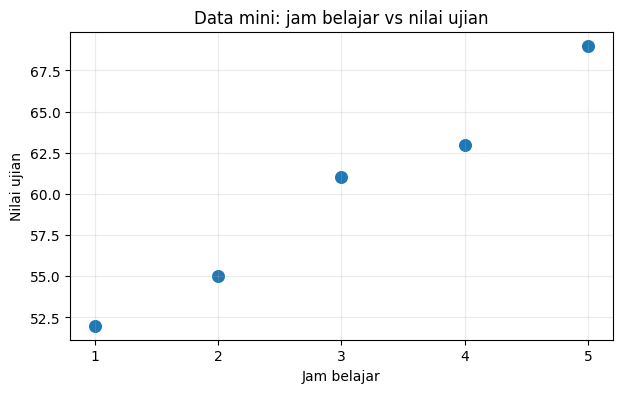

In [2]:
jam = np.array([1, 2, 3, 4, 5], dtype=float)
nilai = np.array([52, 55, 61, 63, 69], dtype=float)

mini = pd.DataFrame({'jam_belajar': jam, 'nilai_ujian': nilai})
display(mini)

plt.figure(figsize=(7, 4))
plt.scatter(jam, nilai, s=70)
plt.title('Data mini: jam belajar vs nilai ujian')
plt.xlabel('Jam belajar')
plt.ylabel('Nilai ujian')
plt.xticks(jam)
plt.grid(alpha=0.25)
plt.show()

**Yang terlihat dari grafik:** titik-titiknya cenderung naik ke kanan. Jadi, ada pola hubungan positif antara jam belajar dan nilai ujian.

Tetap perlu hati-hati: pola ini **belum membuktikan hubungan sebab-akibat**. Bisa saja ada faktor lain, seperti cara belajar, pemahaman materi, atau kualitas tidur.

Berikutnya, pola tadi diubah menjadi persamaan garis supaya bisa dipakai untuk membuat prediksi.


## 3. Hitung slope dan intercept dengan tangan

Ini bagian yang cukup penting. Sebelum mengandalkan library, lebih enak kalau sudah tahu dari mana **slope** dan **intercept** berasal.

Untuk regresi dengan satu variabel X, rumus *ordinary least squares* (OLS) adalah:

$$
 b_1=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sum_{i=1}^{n}(x_i-\bar{x})^2}
$$

$$
 b_0=\bar{y}-b_1\bar{x}
$$

$\bar x$ dan $\bar y$ adalah **rata-rata** X dan y. Simbol $\sum$ artinya semua nilainya dijumlahkan.

**Intuisi slope:** bagian atas rumus melihat apakah X dan y bergerak searah, sedangkan bagian bawah memperhitungkan seberapa bervariasi nilai X. Jika hasil pembilang positif, garisnya cenderung naik.

Supaya tidak bingung, urutannya begini:
1. Hitung rata-rata X dan y.
2. Cari selisih setiap X dan y terhadap rata-ratanya.
3. Kalikan dua selisih tersebut, lalu jumlahkan.
4. Jumlahkan juga kuadrat selisih X.
5. Bagi hasil langkah 3 dengan langkah 4 untuk mendapat slope.
6. Gunakan rata-rata tadi untuk mencari intercept.

**Perlu diingat:** kalau semua X bernilai sama, slope tidak bisa dihitung dengan rumus ini karena penyebutnya nol.


In [3]:
x_bar = np.mean(jam)
y_bar = np.mean(nilai)

perhitungan = pd.DataFrame({
    'x': jam,
    'y': nilai,
    'x - x_bar': jam - x_bar,
    'y - y_bar': nilai - y_bar,
    '(x - x_bar)*(y - y_bar)': (jam - x_bar) * (nilai - y_bar),
    '(x - x_bar)^2': (jam - x_bar)**2,
})

display(perhitungan)
print(f'Rata-rata X = {x_bar:.2f}')
print(f'Rata-rata y = {y_bar:.2f}')

pembilang = np.sum((jam - x_bar) * (nilai - y_bar))
penyebut = np.sum((jam - x_bar)**2)
b1_manual = pembilang / penyebut
b0_manual = y_bar - b1_manual*x_bar

print(f'Pembilang = {pembilang:.2f}')
print(f'Penyebut = {penyebut:.2f}')
print(f'Slope (b1) = {b1_manual:.2f}')
print(f'Intercept (b0) = {b0_manual:.2f}')
print(f'Persamaan: nilai_prediksi = {b0_manual:.2f} + ({b1_manual:.2f} × jam_belajar)')

,x,y,x - x_bar,y - y_bar,(x - x_bar)*(y - y_bar),(x - x_bar)^2
0,1.0,52.0,-2.0,-8.0,16.0,4.0
1,2.0,55.0,-1.0,-5.0,5.0,1.0
2,3.0,61.0,0.0,1.0,0.0,0.0
3,4.0,63.0,1.0,3.0,3.0,1.0
4,5.0,69.0,2.0,9.0,18.0,4.0


Rata-rata X = 3.00
Rata-rata y = 60.00
Pembilang = 42.00
Penyebut = 10.00
Slope (b1) = 4.20
Intercept (b0) = 47.40
Persamaan: nilai_prediksi = 47.40 + (4.20 × jam_belajar)


Dari lima data tadi, persamaan garisnya adalah:

$$\boxed{\hat y=47{,}4+4{,}2x}$$

Artinya, setiap jam belajar bertambah **1 jam**, nilai yang **diprediksi model** naik sekitar **4,2 poin**. Sementara itu, angka **47,4** adalah prediksi garis pada X = 0.

Tapi karena data contoh hanya mencakup 1–5 jam, interpretasi di X = 0 perlu hati-hati. Garis bisa diperpanjang secara matematis, tetapi belum tentu masuk akal untuk konteks nyata.

**Ingat:** slope menunjukkan hubungan dalam data, bukan otomatis bukti sebab-akibat.


## 4. Prediksi, residual, dan kuadrat error

Sekarang persamaannya sudah ada. Kalau jam belajar = 6, tinggal masukkan ke rumus:

$$\hat y=47{,}4+4{,}2(6)=72{,}6$$

Hasilnya **72,6**. Namun, ini tetap perkiraan dari garis model, bukan jaminan nilai ujian sebenarnya. X = 6 juga sedikit di luar rentang data mini yang hanya 1–5 jam.

Lalu, bagaimana mengetahui seberapa jauh hasil model dari data asli? Di sinilah **residual** berguna.

$$ e_i=y_i-\hat y_i $$

Residual = **nilai asli − nilai prediksi**. Jika residual positif, nilai asli lebih tinggi daripada prediksi. Jika negatif, model memprediksi terlalu tinggi.

Metode OLS mencari garis dengan **jumlah kuadrat residual** terkecil:

$$ \mathrm{SSE}=\sum_{i=1}^n (y_i-\hat y_i)^2 $$

Kenapa dikuadratkan? Supaya error positif dan negatif tidak saling menghapus, sekaligus memberi penalti lebih besar untuk kesalahan yang jauh dari garis.


,jam_belajar,nilai_ujian,prediksi,residual,residual_kuadrat
0,1.0,52.0,51.6,0.4,0.16
1,2.0,55.0,55.8,-0.8,0.64
2,3.0,61.0,60.0,1.0,1.00
3,4.0,63.0,64.2,-1.2,1.44
4,5.0,69.0,68.4,0.6,0.36


SSE = 3.60
Prediksi untuk 6 jam belajar = 72.60


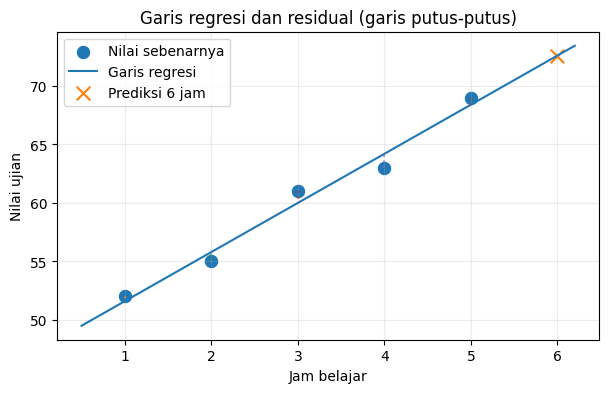

In [4]:
y_hat_mini = b0_manual + b1_manual * jam
residual_mini = nilai - y_hat_mini
sse_mini = np.sum(residual_mini**2)

hasil_mini = mini.copy()
hasil_mini['prediksi'] = y_hat_mini
hasil_mini['residual'] = residual_mini
hasil_mini['residual_kuadrat'] = residual_mini**2

display(hasil_mini)
print(f'SSE = {sse_mini:.2f}')
print(f'Prediksi untuk 6 jam belajar = {b0_manual + b1_manual*6:.2f}')

x_garis = np.linspace(0.5, 6.2, 100)
plt.figure(figsize=(7, 4))
plt.scatter(jam, nilai, s=75, label='Nilai sebenarnya')
plt.plot(x_garis, b0_manual+b1_manual*x_garis, label='Garis regresi')
for x, y_asli, y_pred in zip(jam, nilai, y_hat_mini):
    plt.plot([x, x], [y_asli, y_pred], linestyle=':', alpha=0.7)
plt.scatter([6], [b0_manual+b1_manual*6], marker='x', s=95, label='Prediksi 6 jam')
plt.xlabel('Jam belajar')
plt.ylabel('Nilai ujian')
plt.title('Garis regresi dan residual (garis putus-putus)')
plt.grid(alpha=0.25)
plt.legend()
plt.show()

**Cara membaca grafik:** titik menunjukkan nilai asli, garis lurus adalah hasil model, dan garis putus-putus vertikal menunjukkan selisih antara nilai asli dan prediksi (*residual*).

Tapi ada satu hal penting: garis yang tampak pas di data latihan belum tentu bagus untuk data baru. Karena itu, nanti performanya juga dicek menggunakan **test set**.


## 5. Membandingkan dengan scikit-learn

Setelah melihat rumus manualnya, sekarang coba versi yang lebih praktis dengan `scikit-learn`. Library ini menghitung koefisien regresi secara otomatis.

Ada satu detail Python yang sering membuat bingung di awal:
- `X` perlu berbentuk **2 dimensi**: `(jumlah_baris, jumlah_fitur)`. Untuk 5 data dan 1 fitur, bentuknya `(5, 1)`.
- `y` biasanya **1 dimensi**: `(jumlah_baris,)`.

Itulah alasan fitur satu kolom sering ditulis dengan `.reshape(-1, 1)`. Saat memprediksi satu input menggunakan array, bentuknya juga perlu 2D, misalnya `[[6]]`.


In [5]:
X_mini = jam.reshape(-1, 1)
y_mini = nilai

model_mini = LinearRegression()
model_mini.fit(X_mini, y_mini)

print('Shape X:', X_mini.shape, '| Shape y:', y_mini.shape)
print('Intercept sklearn:', model_mini.intercept_)
print('Slope sklearn:', model_mini.coef_[0])
print('Cocok dengan manual?', np.allclose([b0_manual, b1_manual], [model_mini.intercept_, model_mini.coef_[0]]))

prediksi_6_jam = model_mini.predict(np.array([[6.0]]))[0]
print(f'Prediksi nilai untuk 6 jam = {prediksi_6_jam:.2f}')

Shape X: (5, 1) | Shape y: (5,)
Intercept sklearn: 47.4
Slope sklearn: 4.2
Cocok dengan manual? True
Prediksi nilai untuk 6 jam = 72.60


**Pola dasar yang layak diingat:** `model = LinearRegression()` → `model.fit(X, y)` → `model.predict(X_baru)`.

Di sini belum ada pembagian training dan test. Tujuannya baru satu: memastikan hasil hitung manual dan `scikit-learn` sama. Di bagian berikutnya, alurnya dibuat lebih mirip praktik machine learning yang sebenarnya.


## 6. Latihan dengan data lebih banyak

Kali ini gunakan **60 data simulasi**. Bayangkan satu baris mewakili satu siswa. Nilai ujian dibuat dari pola linear yang ditambah sedikit *noise* acak. Semua angkanya tetap buatan, bukan data sungguhan.

**Kenapa diberi noise?** Karena dalam praktiknya, jarang ada hubungan dua variabel yang benar-benar membentuk garis sempurna. Ada banyak faktor lain yang tidak dimasukkan ke model.

Data dibagi menjadi dua:
- **Training set (80%)**: digunakan untuk mencari slope dan intercept.
- **Test set (20%)**: digunakan untuk mengecek apakah model masih cukup bagus pada data yang belum dipakai belajar.

**Aturan penting:** lakukan `train_test_split` **sebelum** `fit()`. Data test tidak boleh dipakai untuk melatih model atau mengatur model hanya agar skornya terlihat tinggi.


Jumlah data: 60


,jam_belajar,nilai_ujian
0,7.25,78.98
1,5.85,74.46
2,6.68,75.96
3,1.71,48.86
4,6.05,77.92
5,8.85,94.38
6,4.39,65.89
7,1.90,52.52


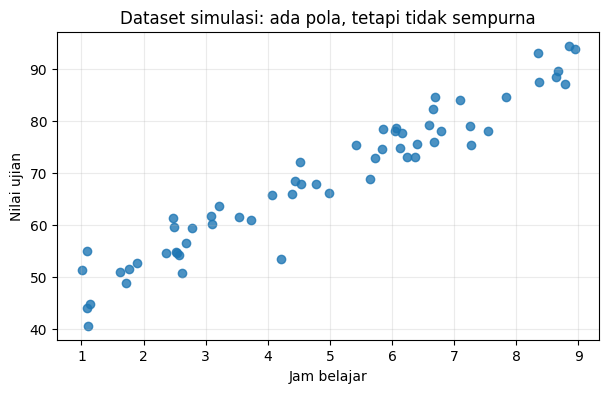

In [6]:
rng = np.random.default_rng(21)
jumlah_data = 60
jam_simulasi = rng.uniform(1, 9, jumlah_data)
noise = rng.normal(loc=0, scale=4, size=jumlah_data)
nilai_simulasi = 42 + 5.5*jam_simulasi + noise

# Pembulatan khusus untuk tampilan; data numerik asli tetap dipakai untuk training.
data = pd.DataFrame({'jam_belajar': jam_simulasi, 'nilai_ujian': nilai_simulasi})
print('Jumlah data:', len(data))
display(data.head(8).round(2))

plt.figure(figsize=(7, 4))
plt.scatter(data['jam_belajar'], data['nilai_ujian'], alpha=0.8)
plt.title('Dataset simulasi: ada pola, tetapi tidak sempurna')
plt.xlabel('Jam belajar')
plt.ylabel('Nilai ujian')
plt.grid(alpha=0.25)
plt.show()

In [7]:
X = data[['jam_belajar']]  # DataFrame, bentuknya dua dimensi
Y = data['nilai_ujian']    # Series, target numerik

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

print(f'Train: {len(X_train)} data | Test: {len(X_test)} data')
print(f'Intercept: {model.intercept_:.3f}')
print(f'Slope: {model.coef_[0]:.3f}')
print(f'Persamaan prediksi: nilai = {model.intercept_:.3f} + {model.coef_[0]:.3f} × jam')

Train: 48 data | Test: 12 data
Intercept: 42.786
Slope: 5.399
Persamaan prediksi: nilai = 42.786 + 5.399 × jam


**Cara membaca hasilnya:** slope menunjukkan perkiraan perubahan nilai ujian ketika jam belajar bertambah 1 jam. Angka koefisien dari training tidak harus persis sama dengan angka yang digunakan untuk membuat data simulasi. Wajar, karena ada noise dan model hanya dilatih memakai sebagian data.

Di grafik berikut, titik training dan test ditampilkan terpisah. Garisnya dihitung dari **training set saja**.


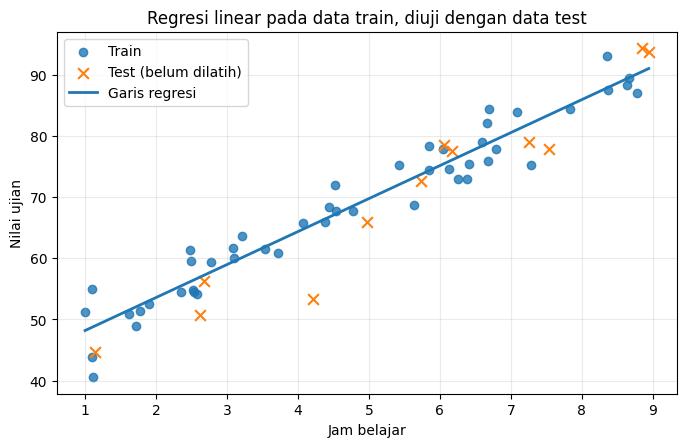

In [8]:
x_plot = np.linspace(X['jam_belajar'].min(), X['jam_belajar'].max(), 200)
y_plot = model.predict(pd.DataFrame({'jam_belajar': x_plot}))

plt.figure(figsize=(8, 4.7))
plt.scatter(X_train['jam_belajar'], y_train, label='Train', alpha=0.8)
plt.scatter(X_test['jam_belajar'], y_test, label='Test (belum dilatih)', marker='x', s=60)
plt.plot(x_plot, y_plot, linewidth=2, label='Garis regresi')
plt.title('Regresi linear pada data train, diuji dengan data test')
plt.xlabel('Jam belajar')
plt.ylabel('Nilai ujian')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 7. Evaluasi dan membaca residual

Model regresi tidak dinilai memakai *accuracy* seperti pada klasifikasi. Ada beberapa metrik yang lebih cocok untuk melihat seberapa jauh prediksi dari nilai aslinya.

| Metrik | Rumus | Cara membacanya |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum |y_i-\hat y_i|$ | Rata-rata selisih absolut. Satuannya sama dengan target (di sini: poin nilai). **Semakin kecil, semakin baik**. |
| **MSE** | $\frac{1}{n}\sum (y_i-\hat y_i)^2$ | Kesalahan dikuadratkan, jadi lebih sensitif terhadap error besar. Satuannya poin². |
| **RMSE** | $\sqrt{\mathrm{MSE}}$ | Kembali ke satuan target, tetapi masih memberi bobot lebih pada error besar dibanding MAE. |
| **$R^2$** | $1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$ | Membandingkan model dengan prediksi konstan memakai rata-rata target pada data yang dinilai. Biasanya makin mendekati 1, makin baik. |

**Hal yang sering tertukar:**
- $R^2=0{,}80$ **bukan** berarti 80% prediksinya benar.
- $R^2$ pada data test bisa **negatif** jika prediksinya lebih buruk daripada baseline rata-rata target test.
- MAE atau RMSE sebesar 4 berarti error sekitar **4 poin nilai**, bukan otomatis 4%.
- Skor training saja belum cukup. Performa pada data yang tidak dipakai melatih biasanya lebih informatif.


In [9]:
def hitung_metrik(y_asli, y_prediksi):
    mae = mean_absolute_error(y_asli, y_prediksi)
    mse = mean_squared_error(y_asli, y_prediksi)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_asli, y_prediksi)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

metrik_train = hitung_metrik(y_train, y_pred_train)
metrik_test = hitung_metrik(y_test, y_pred_test)

tabel_metrik = pd.DataFrame([metrik_train, metrik_test], index=['Train', 'Test'])
display(tabel_metrik.round(3))

,MAE,MSE,RMSE,R2
Train,2.550,10.230,3.198,0.94
Test,3.972,24.323,4.932,0.90


**Coba bandingkan skor train dan test.** Apakah nilainya cukup dekat? Kalau skor train jauh lebih bagus, bisa jadi model kurang mampu bekerja pada data baru.

Namun, test set pada contoh ini hanya berisi 12 baris. Jadi, skornya masih bisa berubah cukup besar kalau pembagian datanya diganti. Jangan terlalu cepat menyimpulkan dari satu angka.

Supaya punya pembanding, cek juga model paling sederhana (*baseline*): **selalu memprediksi nilai rata-rata target pada training set**. Model regresi seharusnya bisa memberi manfaat dibanding tebakan sesederhana itu.


In [10]:
# Baseline dibuat TANPA melihat rata-rata target test.
baseline_test = np.full(len(y_test), y_train.mean())

perbandingan = pd.DataFrame({
    'Baseline (rata-rata train)': hitung_metrik(y_test, baseline_test),
    'Linear Regression': metrik_test,
}).T

display(perbandingan.round(3))
print('Baseline rata-rata training:', round(y_train.mean(), 2))

,MAE,MSE,RMSE,R2
Baseline (rata-rata train),13.876,249.422,15.793,-0.023
Linear Regression,3.972,24.323,4.932,0.900


Baseline rata-rata training: 68.08


### Residual plot: melihat pola kesalahan model

Skor MAE atau R² memang membantu, tetapi kadang ada pola kesalahan yang lebih mudah terlihat lewat grafik residual.

Idealnya, residual tersebar **acak di sekitar garis nol**, tanpa bentuk lengkung atau pola yang makin melebar. Kalau muncul pola yang jelas, mungkin hubungan X dan y tidak cukup linear, atau variasi errornya berubah pada nilai prediksi tertentu.


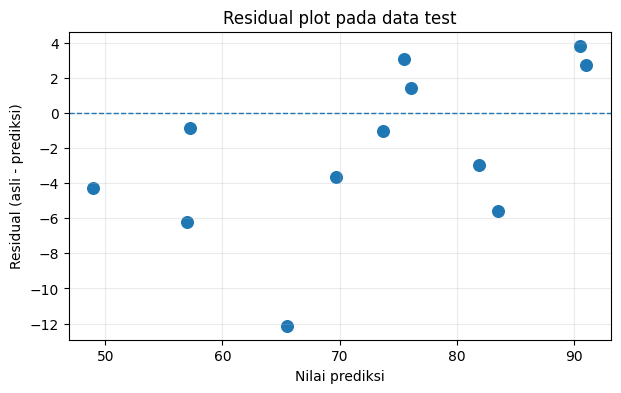

,jam_belajar,nilai_asli,nilai_prediksi,residual
9,1.14,44.69,48.97,-4.28
2,2.62,50.76,56.95,-6.20
4,2.68,56.38,57.23,-0.85
3,4.21,53.41,65.53,-12.12
6,4.98,66.01,69.67,-3.66
5,5.73,72.72,73.74,-1.01
7,6.06,78.59,75.53,3.06


In [11]:
residual_test = np.asarray(y_test) - y_pred_test

plt.figure(figsize=(7, 4))
plt.scatter(y_pred_test, residual_test, s=70)
plt.axhline(0, linestyle='--', linewidth=1)
plt.title('Residual plot pada data test')
plt.xlabel('Nilai prediksi')
plt.ylabel('Residual (asli - prediksi)')
plt.grid(alpha=0.25)
plt.show()

hasil_test = pd.DataFrame({
    'jam_belajar': X_test['jam_belajar'].to_numpy(),
    'nilai_asli': y_test.to_numpy(),
    'nilai_prediksi': y_pred_test,
    'residual': residual_test,
}).sort_values('jam_belajar')
display(hasil_test.head(7).round(2))

### Coba prediksi satu data baru

Bayangkan ada siswa baru yang lama belajarnya sudah diketahui, tetapi nilai ujiannya belum ada. Model dapat digunakan untuk memperkirakan nilai tersebut.

Detail yang perlu diperhatikan: kalau model dilatih memakai DataFrame, nama kolom saat `predict()` sebaiknya sama dengan nama kolom saat `fit()`.


In [12]:
jam_baru = 6.5  # Ubah angka ini untuk bereksperimen
input_baru = pd.DataFrame({'jam_belajar': [jam_baru]})
prediksi_baru = model.predict(input_baru)[0]

print(f'Untuk {jam_baru} jam belajar, prediksi nilai ≈ {prediksi_baru:.2f}')
print('Ini perkiraan dari pola data, BUKAN jaminan nilai sebenarnya.')

Untuk 6.5 jam belajar, prediksi nilai ≈ 77.88
Ini perkiraan dari pola data, BUKAN jaminan nilai sebenarnya.


## 8. Hal yang harus diwaspadai

**1) Tidak semua pola cocok dengan garis lurus.** Kalau sebaran titiknya melengkung, regresi linear sederhana bisa terlalu kaku (*underfitting*).

**2) Outlier bisa menggeser garis.** Karena OLS memakai kuadrat error, satu titik yang sangat ekstrem bisa berpengaruh cukup besar. Tapi jangan langsung menghapus outlier tanpa memeriksa alasannya.

**3) Hubungan tidak selalu berarti sebab-akibat.** Slope positif tidak membuktikan bahwa menambah jam belajar *pasti* menaikkan nilai ujian.

**4) Hati-hati dengan ekstrapolasi.** Model dilatih pada jam belajar sekitar 1–9. Prediksi untuk 25 jam mungkin tidak masuk akal. Pola garis lurus tidak harus berlaku tanpa batas.

**5) Asumsi penting, terutama untuk inferensi statistik.** Beberapa hal yang umum dicek: apakah hubungan cukup linear, pengamatan/error cukup independen, rata-rata error bersyarat mendekati nol, dan variasi error relatif konstan saat memakai standar error klasik. Normalitas residual lebih relevan untuk inferensi pada sampel kecil, **bukan syarat mutlak agar prediksi bisa dibuat**.

**6) Hindari data leakage.** Kalau nanti menggunakan scaling, imputasi, atau pemilihan fitur, proses tersebut dipelajari dari training set saja, lalu diterapkan ke test. Untuk contoh satu fitur ini, scaling belum diperlukan.

**7) Skor bagus belum tentu cukup.** Tetap perhatikan tujuan model, kualitas data, kemungkinan bias, dan apakah prediksi masih masuk akal.

### Eksperimen kecil: bagaimana kalau ada satu outlier?

Gunakan lagi data mini, lalu ubah **satu nilai** menjadi 95. Coba perhatikan apakah posisi dan kemiringan garis ikut berubah. Ini simulasi sederhana untuk melihat sensitivitas OLS.


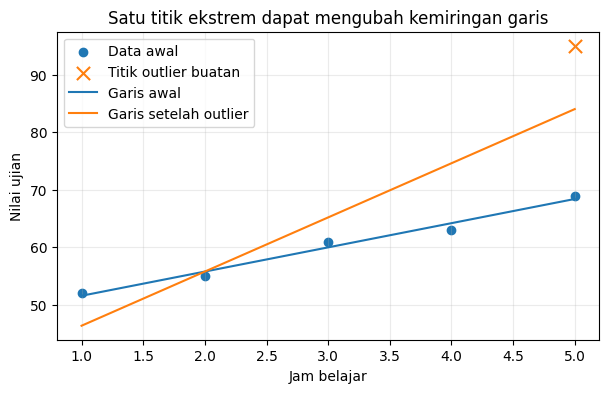

Slope awal: 4.20
Slope dengan outlier: 9.40


In [13]:
nilai_dengan_outlier = nilai.copy()
nilai_dengan_outlier[-1] = 95.0  # nilai pada jam = 5 sengaja dibuat ekstrem

model_asli = LinearRegression().fit(jam.reshape(-1, 1), nilai)
model_outlier = LinearRegression().fit(jam.reshape(-1, 1), nilai_dengan_outlier)

rentang_x = np.linspace(1, 5, 100).reshape(-1, 1)
plt.figure(figsize=(7, 4))
plt.scatter(jam, nilai, label='Data awal')
plt.scatter([5], [95], marker='x', s=90, label='Titik outlier buatan')
plt.plot(rentang_x.ravel(), model_asli.predict(rentang_x), label='Garis awal')
plt.plot(rentang_x.ravel(), model_outlier.predict(rentang_x), label='Garis setelah outlier')
plt.xlabel('Jam belajar')
plt.ylabel('Nilai ujian')
plt.title('Satu titik ekstrem dapat mengubah kemiringan garis')
plt.grid(alpha=0.25)
plt.legend()
plt.show()

print(f'Slope awal: {model_asli.coef_[0]:.2f}')
print(f'Slope dengan outlier: {model_outlier.coef_[0]:.2f}')

## 9. Latihan mandiri

Coba jawab dulu sebelum melihat pembahasan. Tidak perlu langsung benar; yang penting paham alasan di balik jawabannya.

**Latihan 1 — Baca persamaan**

Diberikan model $\hat y=30+7x$.

- a. Berapa prediksi saat $x=4$?
- b. Apa arti slope 7?
- c. Apakah intercept 30 pasti nilai nyata saat $x=0$?

**Latihan 2 — Hitung manual**

Data kecil: $(x,y)=\{(1,3),(2,5),(3,7)\}$. Cari $b_1$, $b_0$, dan prediksi saat $x=4$. Coba gunakan rumus terlebih dahulu, lalu cocokkan dengan Python.

**Latihan 3 — Pahami residual**

Nilai asli 80 dan prediksinya 75. Berapa residualnya? Apa artinya?

**Latihan 4 — Evaluasi**

Model A punya MAE test = 3, sedangkan model B punya MAE test = 7. Keduanya diuji pada **test set dan satuan target yang sama**. Mana yang lebih baik menurut MAE? Apakah cukup memilih model hanya dari informasi itu?

**Latihan 5 — Ubah kode**

Ubah `jam_baru` menjadi 3, lalu 8. Bandingkan hasilnya. Mengapa selisih prediksi tersebut berkaitan dengan slope?

**Latihan 6 — Cek pemahaman**

Apa perbedaan data training dan test? Kenapa performa model tidak cukup dievaluasi dari data training saja?


In [14]:
# Tempat mencoba latihan 2. Isi variabel di bawah setelah menghitung manual.
x_latihan = np.array([1, 2, 3], dtype=float)
y_latihan = np.array([3, 5, 7], dtype=float)

# TODO (boleh isi sendiri):
# b1 = ...
# b0 = ...
# prediksi_x4 = ...
# print(b1, b0, prediksi_x4)

## 10. Jawaban dan ringkasan cepat

### Pembahasan latihan

**1.** a) $30+7(4)=58$. b) Kalau X naik 1 unit, prediksi y naik 7 unit. c) Tidak selalu. X = 0 bisa berada di luar rentang data, atau maknanya kurang relevan untuk kasus tersebut.

**2.** Rata-rata X = 2 dan rata-rata y = 5. Pembilang = $(-1)(-2)+(0)(0)+(1)(2)=4$. Penyebut = $(-1)^2+0^2+1^2=2$. Jadi $b_1=2$ dan $b_0=5-2(2)=1$. Persamaannya $\hat y=1+2x$. Jika $x=4$, prediksinya **9**.

**3.** Residual = $80-75=+5$. Artinya, nilai aslinya 5 poin lebih tinggi daripada prediksi; model menebak terlalu rendah (*underpredict*).

**4.** Model A lebih baik **berdasarkan MAE** karena 3 lebih kecil daripada 7. Namun, pemilihan model tetap perlu mempertimbangkan metrik lain, pola error, stabilitas, kemudahan interpretasi, dan tujuan pemakaian.

**5.** Selisih prediksi antara X = 8 dan X = 3 adalah $b_1(8-3)=5b_1$. Nilai intercept hilang ketika dua prediksi dikurangkan.

**6.** Training dipakai untuk mempelajari koefisien; test dipakai untuk mengecek hasil pada data yang tidak dipakai belajar. Skor training saja sering terlalu optimistis.


In [15]:
# Pengecekan otomatis latihan 2
model_latihan = LinearRegression().fit(x_latihan.reshape(-1, 1), y_latihan)
assert np.isclose(model_latihan.coef_[0], 2)
assert np.isclose(model_latihan.intercept_, 1)
assert np.isclose(model_latihan.predict(np.array([[4.0]]))[0], 9)
print('Latihan 2: slope = 2, intercept = 1, prediksi x=4 adalah 9. ✓')

Latihan 2: slope = 2, intercept = 1, prediksi x=4 adalah 9. ✓


### Cheat sheet untuk dibaca ulang

| Istilah | Inti yang perlu diingat |
|---|---|
| Supervised learning | Belajar dari pasangan input dan target yang diketahui. |
| Simple linear regression | Memakai satu fitur X untuk memprediksi target numerik y dengan garis lurus. |
| Rumus model | $\hat y=b_0+b_1x$ |
| Slope $b_1$ | Perubahan prediksi y saat X naik 1 unit. |
| Intercept $b_0$ | Prediksi y saat X = 0, jika memang masuk akal untuk diinterpretasikan. |
| Residual | Selisih nilai asli dan prediksi: $y-\hat y$. |
| OLS | Memilih koefisien yang meminimalkan $\sum(y-\hat y)^2$. |
| `fit()` | Melatih model menggunakan training data. |
| `predict()` | Menghasilkan prediksi untuk input baru. |
| MAE/RMSE | Ukuran kesalahan prediksi; **semakin kecil, semakin baik**. |
| $R^2$ | Performa relatif terhadap baseline rata-rata; **semakin tinggi biasanya semakin baik**. |
| Outlier | Titik ekstrem yang bisa menarik garis regresi. |
| Extrapolation | Prediksi di luar rentang data training; harus ekstra hati-hati. |

**Kesimpulan singkat:**

> Simple linear regression membuat garis prediksi dari satu fitur. Hal terpenting bukan cuma mendapatkan persamaan, tetapi juga memahami slope dan intercept, membaca residual, lalu mengecek performa model pada data test. Grafik yang terlihat rapi belum tentu berarti modelnya sudah bagus.

**Lanjut belajar apa?** Setelah konsep ini terasa nyaman, urutannya bisa: multiple linear regression → polynomial regression → regularization (Ridge/Lasso) → cross-validation.

---

**Referensi kalau ingin membaca lebih lanjut:**

- [scikit-learn — LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
- [scikit-learn — Regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)
- [scikit-learn — Train/test split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

*Semua data contoh dibuat untuk belajar mandiri, bukan dataset penelitian.*
